In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import xgboost as xgb

In [2]:
waves = pd.read_csv('/Users/rubyestrickland/Desktop/EnvDataSci/HW08/Waves_2023.txt', sep=r'\s+')

In [3]:
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
waves.describe()

,YY,MM,DD,hh,mm,WVHT,DPD,APD,MWD,WTMP
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000
mean,2023.0,6.526063,15.800579,11.499277,40.985594,1.083535,12.161879,6.813054,234.556205,17.196535
std,0.0,3.467253,8.817920,6.925343,15.007646,2.296129,4.165737,2.803208,49.429981,2.564664
min,2023.0,1.000000,1.000000,0.000000,0.000000,0.330000,2.860000,3.420000,10.000000,11.800000
25%,2023.0,4.000000,8.000000,5.000000,26.000000,0.730000,9.090000,5.500000,179.000000,14.600000
50%,2023.0,6.000000,16.000000,11.000000,26.000000,0.880000,12.500000,6.360000,263.000000,17.500000
75%,2023.0,10.000000,23.000000,18.000000,56.000000,1.140000,14.290000,7.550000,271.000000,19.400000
max,2023.0,12.000000,31.000000,23.000000,56.000000,99.000000,99.000000,99.000000,999.000000,23.900000


In [4]:
# WVHT = Wave Height (m)
# DPD = Dominant wave period (seconds)
# APD = Average wave period (seconds)
# MWD = The direction from which the waves at the dominant period (DPD) are coming
# WTMP = Sea surface temperature (Celsius)

waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]

In [5]:
wavesML = waves.drop(['YY','MM','DD','hh','mm'],axis = 1)

In [6]:
df_X = wavesML.drop(['WVHT'],axis=1).to_numpy()
df_y = wavesML['WVHT'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.10)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10)

In [7]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from xgboost import XGBRegressor

In [11]:
model = xgb.XGBRegressor(
    n_estimators=25,     
    max_depth=4,           
    learning_rate=0.1,     
    random_state=42)
model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


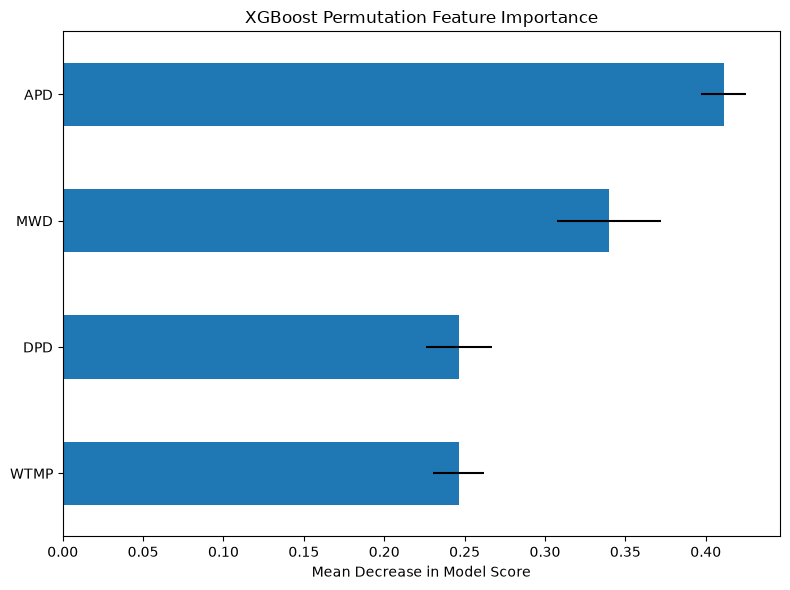

In [20]:
import matplotlib.pyplot as plt
import pandas as pd

# Generate labels: Feature 0, Feature 1, etc.
feature_names = wavesML.drop(['WVHT'],axis=1).columns.tolist()

# Build DataFrame and plot
df_imp = pd.DataFrame(
    {"mean": result.importances_mean, "std": result.importances_std},
    index=feature_names,
).sort_values(by="mean")

fig, ax = plt.subplots(figsize=(8, 6))
df_imp["mean"].plot(kind="barh", xerr=df_imp["std"], ax=ax)

ax.set_title("XGBoost Permutation Feature Importance")
ax.set_xlabel("Mean Decrease in Model Score")
plt.tight_layout()
plt.show()


In [21]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [22]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
model = Ridge(alpha=1.0)
model.fit(X_train_scaled, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

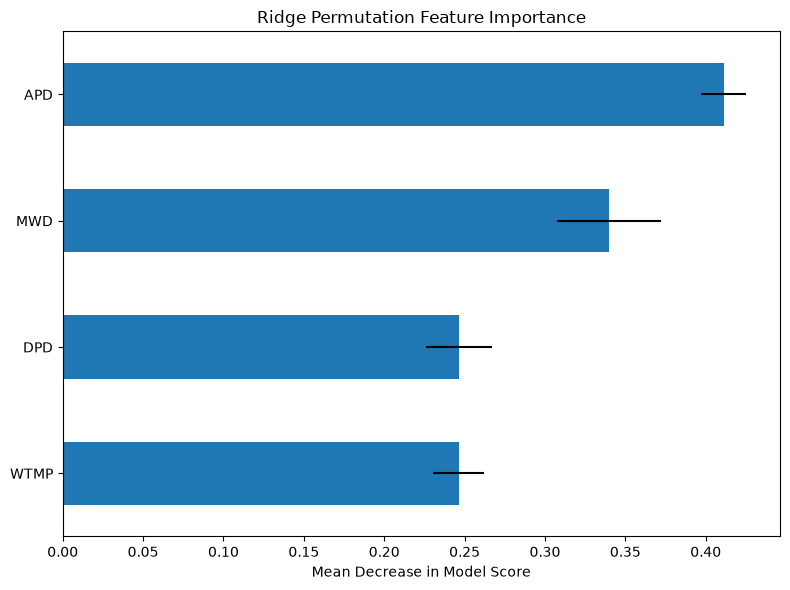

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

# Generate labels: Feature 0, Feature 1, etc.
feature_names = wavesML.drop(['WVHT'],axis=1).columns.tolist()

# Build DataFrame and plot
df_imp = pd.DataFrame(
    {"mean": result.importances_mean, "std": result.importances_std},
    index=feature_names,
).sort_values(by="mean")

fig, ax = plt.subplots(figsize=(8, 6))
df_imp["mean"].plot(kind="barh", xerr=df_imp["std"], ax=ax)

ax.set_title("Ridge Permutation Feature Importance")
ax.set_xlabel("Mean Decrease in Model Score")
plt.tight_layout()
plt.show()

In [26]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import RidgeClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
df = pd.read_csv('/Users/rubyestrickland/Desktop/EnvDataSci/HW05/LA_AQS_2023 (2).csv')
print(df.head())

   State Code  County Code  Site Number  Parameter Code  POC  Latitude  \
0           6           37         1103           68103    1  34.06659   
1           6           37         1103           42602    3  34.06659   
2           6           37         1103           62201    1  34.06659   
3           6           37         1103           62101    1  34.06659   
4           6           37         1103           42603    1  34.06659   

   Longitude  Datum            Parameter Name Duration Description  ... AQI  \
0 -118.22688  WGS84   Ambient Min Temperature              24 HOUR  ...   .   
1 -118.22688  WGS84    Nitrogen dioxide (NO2)               1 HOUR  ...  16   
2 -118.22688  WGS84         Relative Humidity               1 HOUR  ...   .   
3 -118.22688  WGS84       Outdoor Temperature               1 HOUR  ...   .   
4 -118.22688  WGS84  Oxides of nitrogen (NOx)               1 HOUR  ...   .   

  Daily Criteria Indicator  Tribe Name  State Name  County Name    City Name  \


In [27]:
df_O3 = df[(df['Parameter Name']=='Ozone') & (df['Duration Description']=='1 HOUR')]
df_NO2 = df[(df['Parameter Name'] == 'Nitrogen dioxide (NO2)') & (df['Duration Description'] == '1 HOUR')]
df_PM= df[(df['Parameter Name'] == 'PM2.5 - Local Conditions')& (df['Duration Description'] == '1 HOUR')]

In [28]:
df_combined = pd.concat([df_O3, df_NO2, df_PM], axis=1)

In [29]:
df_combined.to_numpy()

array([[6.0, 37.0, 1103.0, ..., nan, nan, nan],
       [6.0, 37.0, 1103.0, ..., nan, nan, nan],
       [6.0, 37.0, 1103.0, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., '1630 N MAIN ST, LOS ANGELES',
        'Los Angeles-Long Beach-Anaheim, CA', 'AQS Data Mart'],
       [nan, nan, nan, ..., '1630 N MAIN ST, LOS ANGELES',
        'Los Angeles-Long Beach-Anaheim, CA', 'AQS Data Mart'],
       [nan, nan, nan, ..., '1630 N MAIN ST, LOS ANGELES',
        'Los Angeles-Long Beach-Anaheim, CA', 'AQS Data Mart']],
      shape=(1636, 102), dtype=object)

In [32]:
df_ozone = df_O3[['Date (Local)', 'Arithmetic Mean']]
df_ozone = df_ozone.rename(columns={'Date (Local)': 'Date', 'Arithmetic Mean': 'Ozone'})
df_noxide = df_NO2[['Date (Local)', 'Arithmetic Mean']]
df_noxide = df_noxide.rename(columns={'Date (Local)': 'Date', 'Arithmetic Mean': 'NO2'})
df_pm = df_PM[['Date (Local)', 'Arithmetic Mean']]
df_pm = df_pm.rename(columns={'Date (Local)': 'Date', 'Arithmetic Mean': 'PM2.5'})

In [33]:
df_combined_o3no2 = pd.merge(
    df_ozone, 
    df_noxide, 
    on="Date")

In [34]:
df_all = pd.merge(
    df_combined_o3no2, 
    df_pm, 
    on="Date")

In [35]:
df_all['Date'] = pd.to_datetime(df_all['Date'])
months = df_all['Date'].dt.month
conditions = [
    months.isin([12, 1, 2]),
    months.isin([6, 7, 8])]
choices = ['Winter', 'Summer']
df_all['Season'] = np.select(conditions, choices, default='Other')

In [36]:
df_filtered = df_all[df_all["Season"].isin(["Summer", "Winter"])].copy()

In [37]:
X = df_filtered[["Ozone", "NO2", "PM2.5"]]
y = (df_filtered["Season"] == "Summer").astype(int)

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

In [39]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [40]:
model = RidgeClassifier(alpha=1.0)
model.fit(X_train_scaled, y_train)

,"alpha alpha: float, default=1.0Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.For an illustration of the effect of alpha on the model coefficients, see:ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If set to false, nointercept will be used in calculations (e.g. data is expected to bealready centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.The default value is determined by scipy.sparse.linalg.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its unbiased and more flexible version named SAGA. Both methods use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from sklearn.preprocessing. .. versionadded:: 0.17 Stochastic Average Gradient descent solver. .. versionadded:: 0.19 SAGA solver.- 'lbfgs' uses L-BFGS-B algorithm implemented in `scipy.optimize.minimize`. It can be used only when `positive` is True.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary <random_state>` for details.",None
Name,Type,Value
"classes_ classes_: n

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.inspection import permutation_importance

# 1. Calculate permutation importance on your scaled test set
result = permutation_importance(
    model, X_test_scaled, y_test, n_repeats=10, random_state=42, n_jobs=-1
)

# 2. Grab feature names from your scaler or unscaled X_train
if "scaler" in locals() and hasattr(scaler, "feature_names_in_"):
    feature_names = scaler.feature_names_in_
elif hasattr(X_train, "columns"):
    feature_names = X_train.columns
else:
    feature_names = [f"Feature {i}" for i in range(X_test_scaled.shape[1])]

# 3. Create a sorted DataFrame and plot the bar chart with Pandas
df_imp = pd.DataFrame(
    {"mean": result.importances_mean, "std": result.importances_std},
    index=feature_names,
).sort_values(by="mean")

ax = df_imp["mean"].plot(
    kind="barh",
    xerr=df_imp["std"],
    figsize=(8, 5),
    title="Permutation Feature Importance",
)
ax.set_xlabel("Mean Decrease in Accuracy")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()
